In [1]:
import numpy as np
import matplotlib.pyplot as plt

from torchvision.datasets import CIFAR10
from torchvision.transforms import v2

from torch.utils.data import DataLoader, Subset

from tqdm import tqdm

from vit import *
from eval import *

from IPython.display import clear_output


Epoch: 445 | train_loss: 0.9323 | train_acc: 69.16 | val_loss: 0.8371 | val_acc: 71.87 | lr: 0.000885



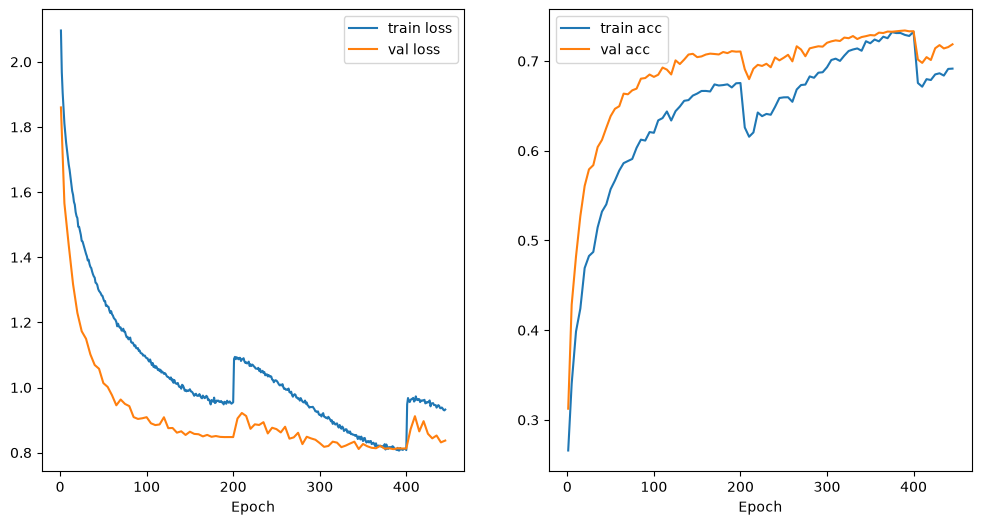

Epoch: 446:  66%|██████▌   | 26240/40000 [00:07<00:02, 5128.44samples/s]

In [ ]:

device = "cuda" if torch.cuda.is_available() else "cpu"

val_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(dtype=torch.float32, scale=True),
    v2.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

train_transform = v2.Compose([
    val_transform,
    # v2.RandomCrop(size = 32, padding=2),
    # v2.RandomHorizontalFlip(p=0.5),
    # v2.RandomRotation(degrees=30),
    v2.RandAugment(num_ops=2, magnitude=5)
])



train_dataset = CIFAR10(root="data", train=True, transform=train_transform, download=True)
val_dataset = CIFAR10(root="data", train=True, transform=val_transform, download=True)
test_dataset = CIFAR10(root="data", train=False, transform=val_transform, download=True)

torch.manual_seed(42)

val_ratio = 0.2
num_val_samples = int(val_ratio * len(train_dataset))
num_train_samples = len(train_dataset) - num_val_samples

indices = torch.randperm(len(train_dataset))

train_indices = indices[:num_train_samples]
val_indices = indices[num_train_samples:]

train_dataset = Subset(train_dataset, train_indices)
val_dataset = Subset(val_dataset, val_indices)

# for i, sample in enumerate(train_dataset):
#     if (i < 10):
#         sample[0].show()
#         print(sample[1])

batch_size = 128

train_dataloader = DataLoader(
    train_dataset,
    batch_size = batch_size,
    shuffle = True,
    num_workers=16,
    pin_memory=True
)

val_dataloader = DataLoader(
    val_dataset,
    batch_size = batch_size,
    shuffle = False,
    num_workers=16,
    pin_memory=True
)

test_dataloader = DataLoader(
    test_dataset,
    batch_size = batch_size,
    shuffle = False,
    num_workers=16,
    pin_memory=True
)

config = ViTConfig()
model = ViT(config).to(device)

epochs = 1000
lr = 1e-3
weight_decay = 1e-2  

optimizer = torch.optim.AdamW(
    params=model.parameters(), 
    lr=lr, 
    weight_decay=weight_decay
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer,
    T_0=epochs // 5
)
loss_fn = torch.nn.CrossEntropyLoss()

train_losses = []
val_losses = []

train_accs = []
val_accs = []

train_epochs = []
val_epochs = []


for epoch in range(epochs):
    current_lr = scheduler.get_last_lr()[0]
    pbar = tqdm(total=num_train_samples, unit="samples", desc = f"Epoch: {epoch+1}")

    train_loss = 0.0

    model.train()
    for i, train_batch in enumerate(train_dataloader):
        x_train, y_train = train_batch
        x_train, y_train = x_train.to(device), y_train.to(device)

        optimizer.zero_grad()

        logits = model(x_train)

        loss = loss_fn(logits, y_train)
        train_loss += loss.item()


        loss.backward()
        optimizer.step()

        pbar.update(len(x_train))

    pbar.close()
    scheduler.step()

    train_losses.append(train_loss / len(train_dataloader))
    train_epochs.append(epoch+1)

    if (epoch == 0 or (epoch+1) % 5 == 0):
        model.eval()

        train_correct_preds = 0

        val_correct_preds = 0
        val_loss = 0.0

        # must go here because dropout should be disabled
        for i, train_batch in enumerate(train_dataloader):
            x_train, y_train = train_batch
            x_train, y_train = x_train.to(device), y_train.to(device)

            logits = model(x_train)
            train_correct_preds += correct_preds(logits, y_train)

        for i, val_batch in enumerate(val_dataloader):
            x_val, y_val = val_batch
            x_val, y_val = x_val.to(device), y_val.to(device)

            logits = model(x_val)

            loss = loss_fn(logits, y_val)
            val_loss += loss.item()
            
            val_correct_preds += correct_preds(logits, y_val)

        val_losses.append(val_loss / len(val_dataloader))
        train_accs.append(train_correct_preds / num_train_samples)
        val_accs.append(val_correct_preds / num_val_samples)
        val_epochs.append(epoch+1)


        clear_output(wait=True)

        print(f"Epoch: {epoch+1} | "
              f"train_loss: {train_loss / len(train_dataloader) :.4f} | "
              f"train_acc: {100 * train_correct_preds / num_train_samples:.2f} | "
              f"val_loss: {val_loss / len(val_dataloader) :.4f} | "
              f"val_acc: {100 * val_correct_preds / num_val_samples :.2f} | "
              f"lr: {current_lr :.6f}\n"
        ) 


        plt.figure(figsize = (12, 6))

        plt.subplot(121)
        plt.plot(train_epochs, train_losses, label = "train loss")
        plt.plot(val_epochs, val_losses, label = "val loss")
        plt.xlabel("Epoch")
        plt.legend()

        plt.subplot(122)
        plt.plot(val_epochs, train_accs, label = "train acc")
        plt.plot(val_epochs, val_accs, label = "val acc")
        plt.xlabel("Epoch")
        plt.legend()

        plt.show()

# LEARN: LR schedulers, pytorch broadcasting